In [21]:
import pandas as pd
import numpy as np
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, log_loss, 
                             classification_report, average_precision_score, precision_recall_curve)
from catboost import CatBoostClassifier

import optuna

import warnings
warnings.filterwarnings("ignore")

In [22]:
# Import the data since we want to be able to change our experiments individually.
Xt = pd.read_csv("modeling_data/train.csv")
yt = Xt["target"]
Xt.drop(columns=["target"],inplace=True)
Xv = pd.read_csv("modeling_data/validation.csv")
yv = Xv["target"]
Xv.drop(columns=["target"],inplace=True)

Xt.drop(columns=["patient_nbr"],inplace=True)
Xv.drop(columns=["patient_nbr"],inplace=True)

In [23]:
# prepare for catboost
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]


# careful! catboost demands categorical columns to have string entry
Xt_cb, Xv_cb = Xt.copy(), Xv.copy()
for c in cat_cols:
    for df in (Xt_cb, Xv_cb):
        df[c] = df[c].astype(object).where(df[c].notna(), "missing").astype(str)

In [24]:
spw = float((yt == 0).sum() / (yt == 1).sum())

In [ ]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42),)

# Include a configuration as the first trial.
study.enqueue_trial({
    "iterations": 1000,
    "learning_rate": 0.05,
    "depth": 5,
    "l2_leaf_reg": 2.0,
    "scale_pos_weight": spw,
})

best_f1 = -1.0

for _ in range(50):
    trial = study.ask()

    candidate = CatBoostClassifier(
        iterations=trial.suggest_int("iterations", 100, 5_000, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.001, 0.5, log=True),
        depth=trial.suggest_int("depth", 2, 10),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 50.0, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 1.0, spw+5, log=True),
        loss_function="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )

    candidate.fit(Xt_cb, yt, cat_features=cat_cols)
    trial_proba = candidate.predict_proba(Xv_cb)[:, 1]

    # chooses a new optimal threshold
    p, r, thr = precision_recall_curve(yv, trial_proba)
    f1s = (
        2 * p[:-1] * r[:-1]
        / np.maximum(p[:-1] + r[:-1], 1e-15)
    )

    best_index = int(np.argmax(f1s))
    trial_f1 = float(f1s[best_index])
    trial_threshold = float(thr[best_index])

    trial.set_user_attr("threshold", trial_threshold)
    study.tell(trial, trial_f1)

    # keep the winning model for later use
    if trial_f1 > best_f1:
        best_f1 = trial_f1
        model = candidate
        proba = trial_proba
        threshold = trial_threshold

    print(
        f"Trial {trial.number:02d} | "
        f"F1={trial_f1:.4f} | "
        f"threshold={trial_threshold:.4f} | "
        f"best={best_f1:.4f}"
    )

y_pred = (proba >= threshold).astype(int)

print("\nBest parameters:", study.best_params)
print(f"Best threshold: {threshold:.4f}")
print(f"F1 @0.5: {f1_score(yv, proba >= 0.5):.4f}")
print(f"Threshold-optimized F1: {best_f1:.4f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(classification_report(yv, y_pred, digits=4, zero_division=0))

[I 2026-10-24 20:10:39,147] A new study created in memory with name: no-name-43493b31-680b-4384-b0b9-f284af1b0416


Trial 00 | F1=0.2909 | threshold=0.5778 | best=0.2909
Trial 01 | F1=0.2389 | threshold=0.0250 | best=0.2909
Trial 02 | F1=0.2881 | threshold=0.4975 | best=0.2909
Trial 03 | F1=0.2408 | threshold=0.1234 | best=0.2909
Trial 04 | F1=0.2910 | threshold=0.2441 | best=0.2910
Trial 05 | F1=0.2891 | threshold=0.3845 | best=0.2910
Trial 06 | F1=0.2924 | threshold=0.1836 | best=0.2924
Trial 07 | F1=0.2871 | threshold=0.6556 | best=0.2924
Trial 08 | F1=0.2882 | threshold=0.3228 | best=0.2924
Trial 09 | F1=0.2885 | threshold=0.2418 | best=0.2924
Trial 10 | F1=0.2824 | threshold=0.1598 | best=0.2924
Trial 11 | F1=0.2933 | threshold=0.1557 | best=0.2933
Trial 12 | F1=0.2937 | threshold=0.1698 | best=0.2937
Trial 13 | F1=0.2933 | threshold=0.1487 | best=0.2937
Trial 14 | F1=0.2940 | threshold=0.3060 | best=0.2940
Trial 15 | F1=0.2508 | threshold=0.2167 | best=0.2940
Trial 16 | F1=0.2859 | threshold=0.2875 | best=0.2940
Trial 17 | F1=0.2869 | threshold=0.3931 | best=0.2940
Trial 18 | F1=0.2949 | thres

In [39]:
best_parameters = {'iterations': 2900, 'learning_rate': 0.015816774743430746, 'depth': 6, 'l2_leaf_reg': 12.487447215396557, 'scale_pos_weight': 3.3504967721289862} 
best_threshold = 0.3705

cbc = CatBoostClassifier(**best_parameters,
        verbose=100,
        loss_function="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=42,
        allow_writing_files=False)
cbc.fit(Xt_cb,yt, cat_features=cat_cols)

0:	learn: 0.6891195	total: 38.4ms	remaining: 1m 51s
100:	learn: 0.5710581	total: 4.5s	remaining: 2m 4s
200:	learn: 0.5607645	total: 8.77s	remaining: 1m 57s
300:	learn: 0.5565443	total: 12.8s	remaining: 1m 50s
400:	learn: 0.5536649	total: 16.9s	remaining: 1m 45s
500:	learn: 0.5511620	total: 20.8s	remaining: 1m 39s
600:	learn: 0.5488520	total: 24.7s	remaining: 1m 34s
700:	learn: 0.5465641	total: 28.7s	remaining: 1m 29s
800:	learn: 0.5443901	total: 32.6s	remaining: 1m 25s
900:	learn: 0.5421764	total: 36.5s	remaining: 1m 21s
1000:	learn: 0.5401871	total: 40.6s	remaining: 1m 16s
1100:	learn: 0.5379546	total: 44.7s	remaining: 1m 12s
1200:	learn: 0.5358509	total: 48.7s	remaining: 1m 8s
1300:	learn: 0.5340037	total: 52.7s	remaining: 1m 4s
1400:	learn: 0.5320062	total: 56.7s	remaining: 1m
1500:	learn: 0.5300919	total: 1m	remaining: 56.7s
1600:	learn: 0.5281499	total: 1m 5s	remaining: 52.8s
1700:	learn: 0.5261707	total: 1m 9s	remaining: 48.7s
1800:	learn: 0.5243003	total: 1m 13s	remaining: 44.7s

CatBoostClassifier(allow_writing_files=False, depth=6, devices='0', iterations=2900, l2_leaf_reg=12.487447215396557, learning_rate=0.015816774743430746, loss_function='Logloss', random_seed=42, scale_pos_weight=3.3504967721289862, task_type='GPU', verbose=100)

In [94]:
proba = cbc.predict_proba(Xv_cb)[:, 1]

threshold = 0.5
y_pred = (proba >= threshold).astype(int)

print("ROC-AUC:", round(roc_auc_score(yv, proba), 4))
print("PR-AUC: ", round(average_precision_score(yv, proba), 4))
print(f"Accuracy: {accuracy_score(yv, y_pred):.3f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(f"\n\n{classification_report(yv, y_pred)}")
print(f"\nF1 @{threshold}: {round(f1_score(yv,y_pred),4)}")

# Best-threshold F1 (optimistic: threshold chosen on Xv itself)
p, r, thr = precision_recall_curve(yv, proba)
f1s = 2 * p * r / (p + r + 1e-12)
best = f1s[:-1].argmax()
print(f"\nBest-threshold F1: {f1s[best]:.4f} at threshold {thr[best]:.4f}")

ROC-AUC: 0.6841
PR-AUC:  0.2411
Accuracy: 0.870

Confusion matrix:
 [[13876   590]
 [ 1521   296]]


              precision    recall  f1-score   support

           0       0.90      0.96      0.93     14466
           1       0.33      0.16      0.22      1817

    accuracy                           0.87     16283
   macro avg       0.62      0.56      0.57     16283
weighted avg       0.84      0.87      0.85     16283


F1 @0.5: 0.219

Best-threshold F1: 0.2980 at threshold 0.3758


# Error Analysis

In [95]:
Xv["target"]=yv
Xv["y_pred"]=y_pred

In [96]:
Errors = Xv[Xv["target"] != Xv["y_pred"]]

In [97]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,target,y_pred
3,7,62,0,11,0,0,0,7,AfricanAmerican,Male,...,Steady,No,No,No,No,No,Ch,Yes,1,0
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,...,Down,No,No,No,No,No,Ch,Yes,0,1
28,5,47,1,6,0,0,0,5,Caucasian,Male,...,No,No,No,No,No,No,No,No,1,0
29,2,18,0,15,5,1,0,3,Caucasian,Female,...,Down,No,No,No,No,No,Ch,Yes,1,0
40,8,35,2,9,0,0,0,9,AfricanAmerican,Female,...,No,No,No,No,No,No,No,No,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16252,4,26,0,10,0,0,1,7,AfricanAmerican,Female,...,Steady,No,No,No,No,No,Ch,Yes,0,1
16260,2,43,0,24,2,0,1,7,Caucasian,Female,...,Steady,No,No,No,No,No,Ch,Yes,1,0
16265,3,61,0,19,1,0,1,9,Caucasian,Male,...,Steady,No,No,No,No,No,Ch,Yes,1,0
16272,4,9,0,14,0,0,1,9,Caucasian,Female,...,No,No,No,No,No,No,No,Yes,1,0


In [98]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,target,y_pred
3,7,62,0,11,0,0,0,7,AfricanAmerican,Male,...,Steady,No,No,No,No,No,Ch,Yes,1,0
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,...,Down,No,No,No,No,No,Ch,Yes,0,1
28,5,47,1,6,0,0,0,5,Caucasian,Male,...,No,No,No,No,No,No,No,No,1,0
29,2,18,0,15,5,1,0,3,Caucasian,Female,...,Down,No,No,No,No,No,Ch,Yes,1,0
40,8,35,2,9,0,0,0,9,AfricanAmerican,Female,...,No,No,No,No,No,No,No,No,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16252,4,26,0,10,0,0,1,7,AfricanAmerican,Female,...,Steady,No,No,No,No,No,Ch,Yes,0,1
16260,2,43,0,24,2,0,1,7,Caucasian,Female,...,Steady,No,No,No,No,No,Ch,Yes,1,0
16265,3,61,0,19,1,0,1,9,Caucasian,Male,...,Steady,No,No,No,No,No,Ch,Yes,1,0
16272,4,9,0,14,0,0,1,9,Caucasian,Female,...,No,No,No,No,No,No,No,Yes,1,0


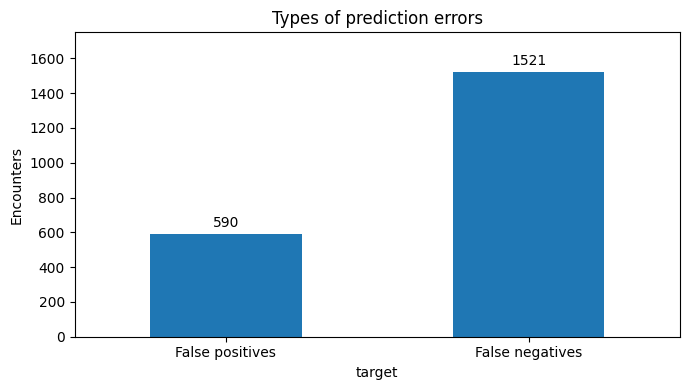

In [105]:
import pandas as pd
import matplotlib.pyplot as plt

audit = Xv.copy()

audit["result"] = "TN"
audit.loc[audit["target"].eq(0) & audit["y_pred"].eq(1), "result"] = "FP"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(0), "result"] = "FN"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(1), "result"] = "TP"

error_counts = (Errors["target"].map({0: "False positives", 1: "False negatives"}).value_counts().reindex(["False positives", "False negatives"], fill_value=0))

ax = error_counts.plot.bar(figsize=(7, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_ylabel("Encounters")
ax.set_title("Types of prediction errors")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

number_inpatient        number_emergency        time_in_hospital  \
                   mean median             mean median             mean   
result                                                                    
FP                 2.92    3.0             0.66    0.0             5.11   
TP                 3.40    3.0             0.96    0.0             4.95   

              num_medications         
       median            mean median  
result                                
FP        5.0           18.35   18.0  
TP        4.0           18.82   18.0

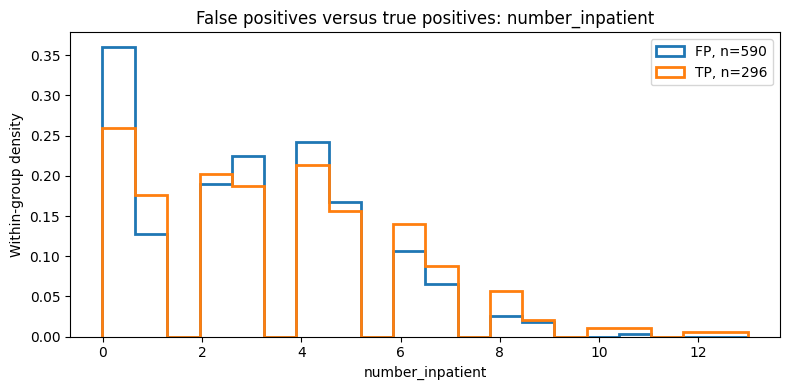

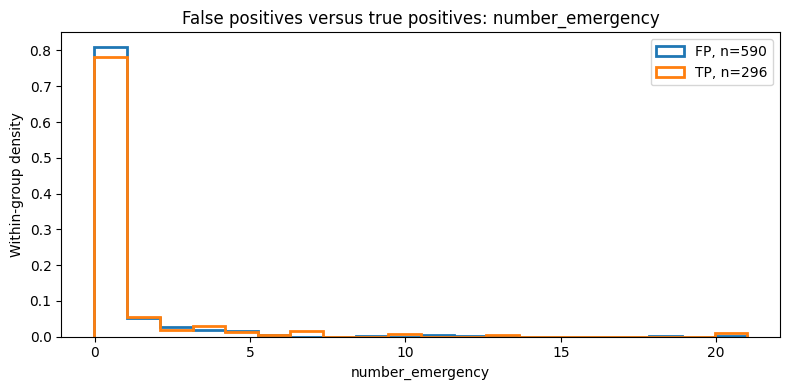

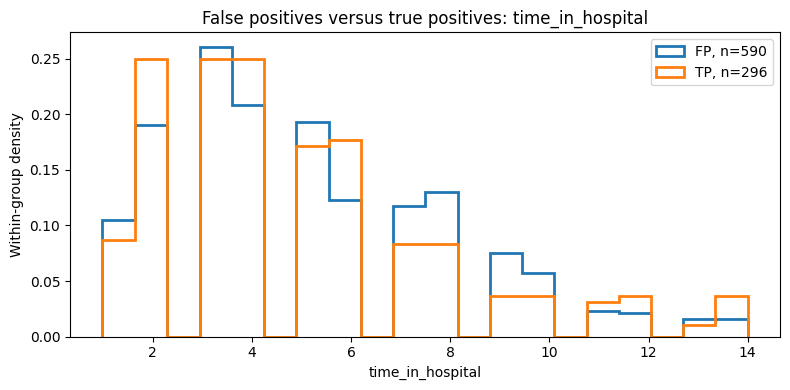

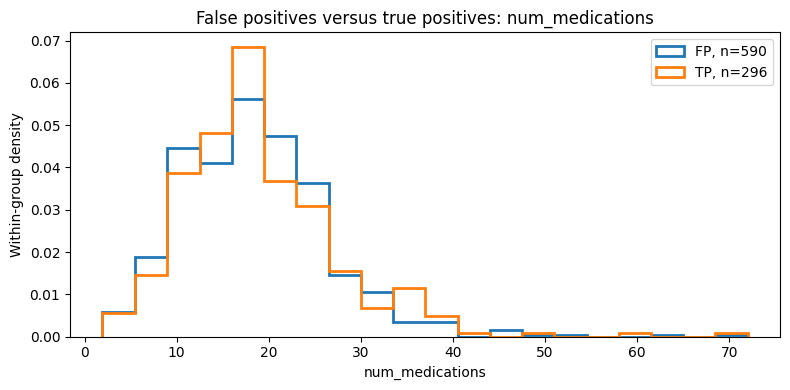

In [106]:
flagged = audit.loc[audit["y_pred"].eq(1)].copy()

columns = ["number_inpatient", "number_emergency", "time_in_hospital", "num_medications",]

display(flagged.groupby("result")[columns].agg(["mean", "median"]).round(2))

for column in columns:
    values = pd.to_numeric(flagged[column], errors="coerce")

    if values.notna().sum() == 0:
        continue

    # Use identical bin edges for both groups.
    edges = pd.cut(values.dropna(), bins=20, retbins=True)[1]

    plt.figure(figsize=(8, 4))

    for result in ["FP", "TP"]:
        group = values.loc[flagged["result"].eq(result)].dropna()

        if not group.empty:
            plt.hist(
                group,
                bins=edges,
                density=True,
                histtype="step",
                linewidth=2,
                label=f"{result}, n={len(group):,}",
            )

    plt.xlabel(column)
    plt.ylabel("Within-group density")
    plt.title(f"False positives versus true positives: {column}")
    plt.legend()
    plt.tight_layout()
    plt.show()

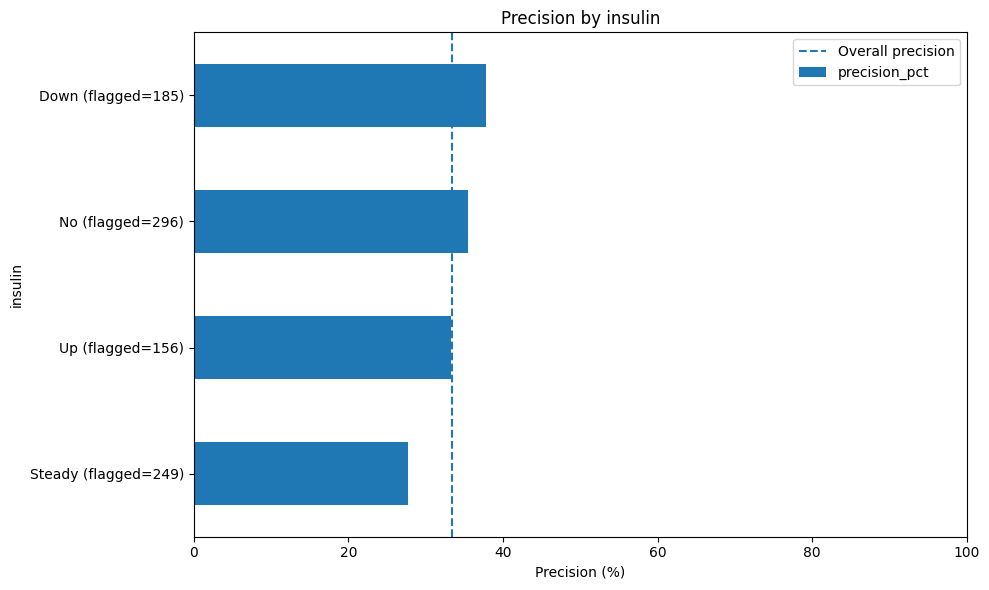

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
insulin,,,,,,,,
No,6529,191,673,105,296,35.47,2.84,86.50
Steady,4236,180,457,69,249,27.71,4.08,86.88
Down,1630,115,213,70,185,37.84,6.59,75.27
Up,1481,104,178,52,156,33.33,6.56,77.39


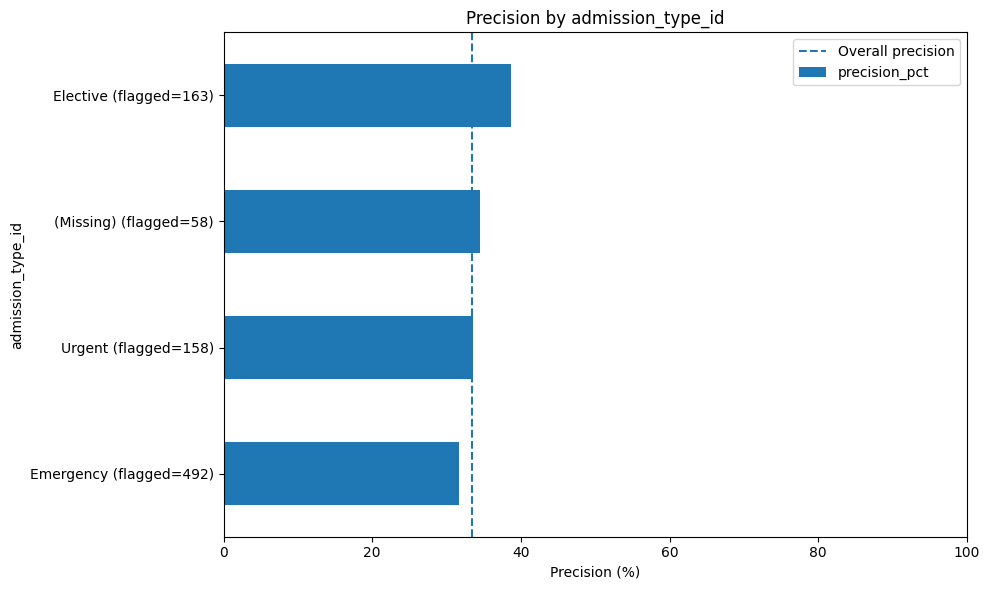

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
admission_type_id,,,,,,,,
Emergency,7292,336,856,156,492,31.71,4.40,84.58
Urgent,2496,105,264,53,158,33.54,4.04,83.28
Elective,2671,100,249,63,163,38.65,3.61,79.81
(Missing),699,38,71,20,58,34.48,5.16,78.02
Not Available,654,9,77,3,12,25.00,1.36,96.25
Not Mapped,56,2,4,1,3,33.33,3.45,80.00
Newborn,3,0,0,0,0,NaN,0.00,NaN
Trauma Center,5,0,0,0,0,NaN,0.00,NaN


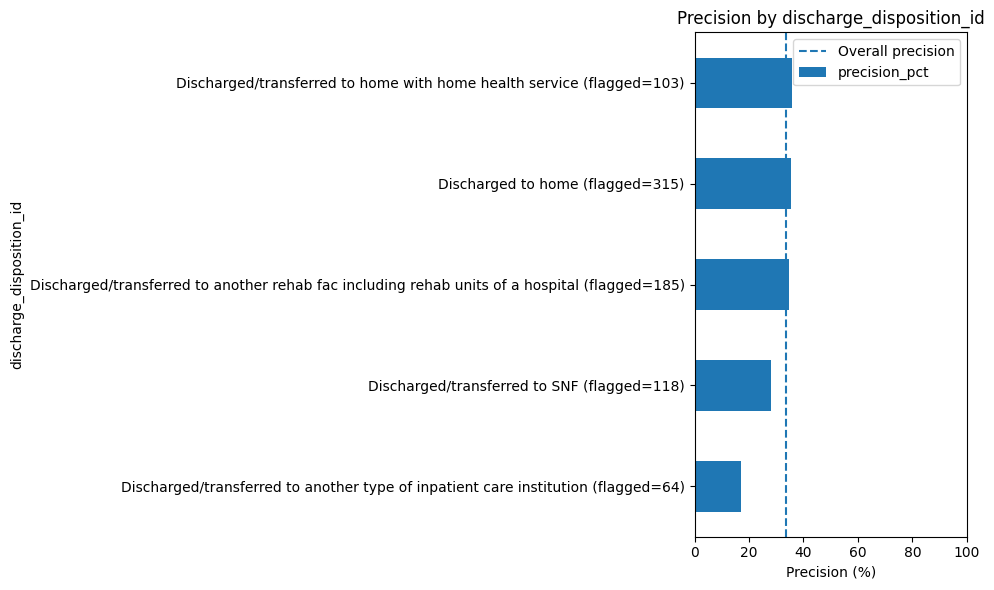

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
discharge_disposition_id,,,,,,,,
Discharged to home,8518,203,791,112,315,35.56,2.33,87.60
Discharged/transferred to another rehab fac including rehab units of a hospital,111,121,37,64,185,34.59,52.16,36.63
Discharged/transferred to SNF,1810,85,289,33,118,27.97,4.49,89.75
Discharged/transferred to home with home health service,1667,66,210,37,103,35.92,3.81,85.02
Discharged/transferred to another type of inpatient care institution,132,53,33,11,64,17.19,28.65,75.00
Discharged/transferred to another short term hospital,285,22,32,22,44,50.00,7.17,59.26
Discharged/transferred/referred to a psychiatric hospital of psychiatric distinct part unit of a hospital,10,7,2,7,14,50.00,41.18,22.22
(Missing),516,7,70,1,8,12.50,1.34,98.59
Discharged/transferred to ICF,112,7,14,4,11,36.36,5.88,77.78


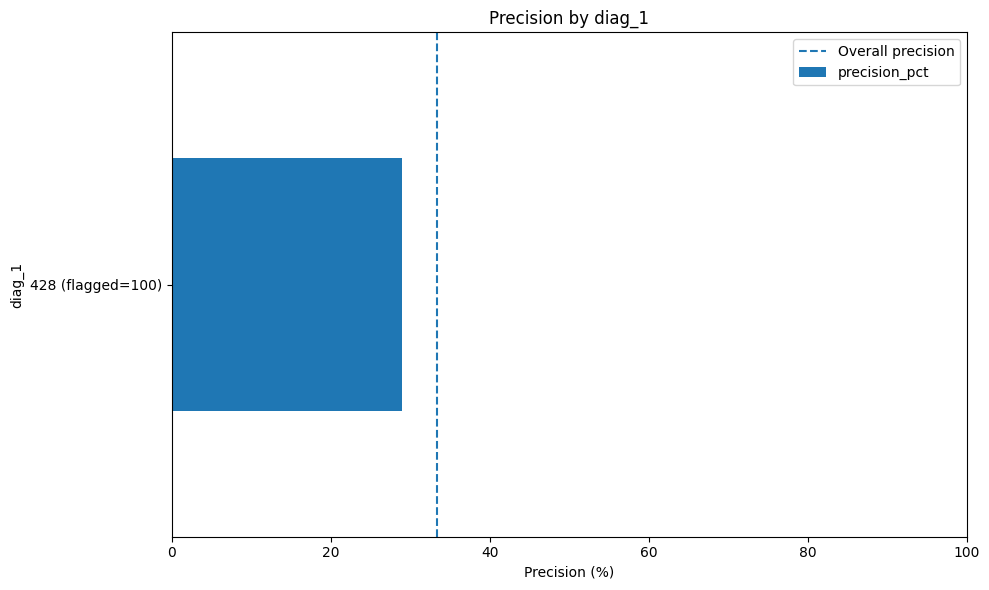

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
diag_1,,,,,,,,
428,863,71,127,29,100,29.00,7.60,81.41
434,242,29,40,18,47,38.30,10.70,68.97
250.6,127,28,33,15,43,34.88,18.06,68.75
820,115,22,16,12,34,35.29,16.06,57.14
486,507,20,37,8,28,28.57,3.80,82.22
996,239,19,36,7,26,26.92,7.36,83.72
715,302,15,22,11,26,42.31,4.73,66.67
584,218,15,24,4,19,21.05,6.44,85.71
276,242,15,42,9,24,37.50,5.84,82.35


In [101]:
group_tables = {}
overall_precision = 100 * flagged["target"].mean()

for column in [
    "insulin",
    "admission_type_id",
    "discharge_disposition_id",
    "diag_1",
]:
    groups = audit[column].astype("string").fillna("(Missing)")

    table = pd.crosstab(
        groups, audit["result"]
    ).reindex(columns=["TN", "FP", "FN", "TP"], fill_value=0)

    table["flagged"] = table["TP"] + table["FP"]
    negatives = table["TN"] + table["FP"]
    positives = table["TP"] + table["FN"]

    table["precision_pct"] = (
        100 * table["TP"]
        / table["flagged"].where(table["flagged"] > 0)
    )

    table["FPR_pct"] = (
        100 * table["FP"] / negatives.where(negatives > 0)
    )

    table["FNR_pct"] = (
        100 * table["FN"] / positives.where(positives > 0)
    )

    group_tables[column] = table

    # Show common groups with at least 50 positive predictions.
    shown = (
        table.loc[table["flagged"] >= 50]
        .nlargest(12, "flagged")
        .sort_values("precision_pct")
    )

    if shown.empty:
        continue

    ax = shown["precision_pct"].plot.barh(figsize=(10, 6))

    ax.set_yticks(
        range(len(shown)),
        [
            f"{group} (flagged={int(n):,})"
            for group, n in shown["flagged"].items()
        ],
    )

    ax.axvline(
        overall_precision,
        linestyle="--",
        label="Overall precision",
    )

    ax.set_xlim(0, 100)
    ax.set_xlabel("Precision (%)")
    ax.set_title(f"Precision by {column}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Rank by the actual number of false positives.
    display(
        table.sort_values("FP", ascending=False)
        .head(12)
        .round(2)
    )

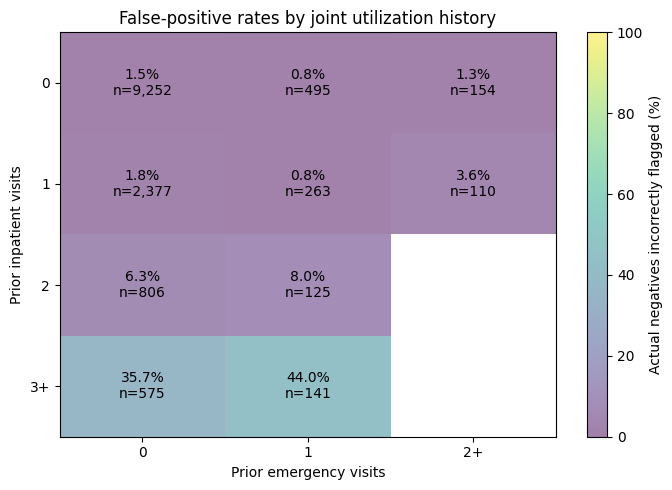

actual_negatives  false_positives    FPR
inpatient_band emergency_band                                          
0              0                           9252              135  0.015
               1                            495                4  0.008
               2+                           154                2  0.013
1              0                           2377               43  0.018
               1                            263                2  0.008
               2+                           110                4  0.036
2              0                            806               51  0.063
               1                            125               10  0.080
               2+                            69               12  0.174
3+             0                            575              205  0.357
               1                            141               62  0.440
               2+                            99               60  0.606

In [102]:
audit["inpatient_band"] = pd.cut(
    pd.to_numeric(audit["number_inpatient"], errors="coerce"),
    bins=[-float("inf"), 0, 1, 2, float("inf")],
    labels=["0", "1", "2", "3+"],
)

audit["emergency_band"] = pd.cut(
    pd.to_numeric(audit["number_emergency"], errors="coerce"),
    bins=[-float("inf"), 0, 1, float("inf")],
    labels=["0", "1", "2+"],
)

negative = audit.loc[audit["target"].eq(0)]

joint = (
    negative.groupby(
        ["inpatient_band", "emergency_band"], observed=True
    )["y_pred"]
    .agg(
        actual_negatives="size",
        false_positives="sum",
        FPR="mean",
    )
)

counts = (
    joint["actual_negatives"]
    .unstack()
    .reindex(
        index=["0", "1", "2", "3+"],
        columns=["0", "1", "2+"],
    )
    .fillna(0)
)

rates = 100 * joint["FPR"].unstack().reindex_like(counts)
shown = rates.where(counts >= 100)

plt.figure(figsize=(7, 5))
plt.imshow(
    shown.to_numpy(dtype=float),
    aspect="auto",
    vmin=0,
    vmax=100,
    alpha=0.5,
)

plt.xticks(range(len(shown.columns)), shown.columns)
plt.yticks(range(len(shown.index)), shown.index)

for i in range(len(shown.index)):
    for j in range(len(shown.columns)):
        if pd.notna(shown.iloc[i, j]):
            plt.text(
                j, i,
                f"{shown.iloc[i, j]:.1f}%\nn={int(counts.iloc[i, j]):,}",
                ha="center",
                va="center",
            )

plt.xlabel("Prior emergency visits")
plt.ylabel("Prior inpatient visits")
plt.title("False-positive rates by joint utilization history")
plt.colorbar(label="Actual negatives incorrectly flagged (%)")
plt.tight_layout()
plt.show()

display(joint.round(3))

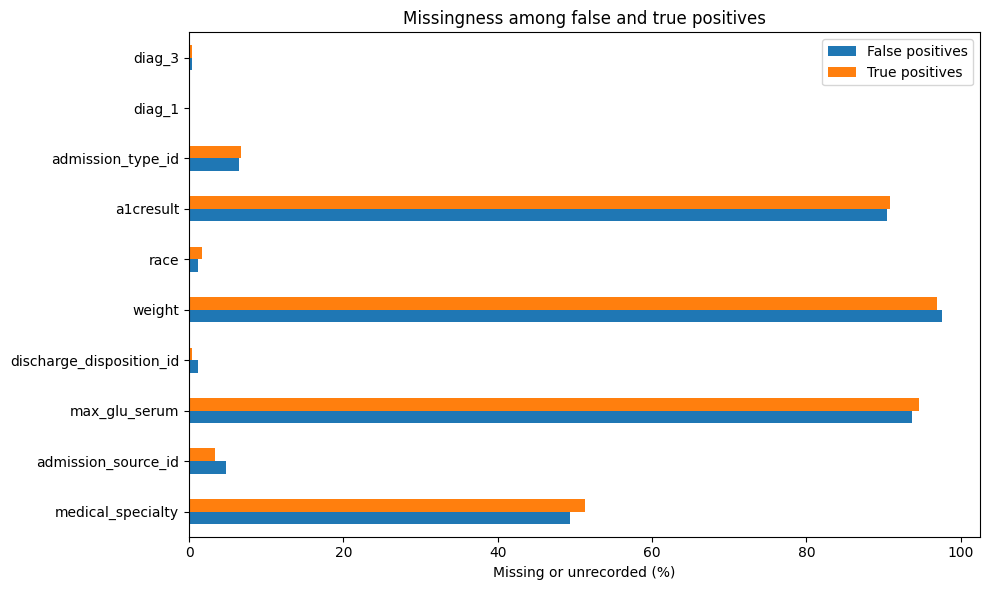

,False positives,True positives,difference_percentage_points
medical_specialty,49.32,51.35,-2.03
admission_source_id,4.75,3.38,1.37
max_glu_serum,93.73,94.59,-0.87
discharge_disposition_id,1.19,0.34,0.85
weight,97.63,96.96,0.67
race,1.19,1.69,-0.50
a1cresult,90.51,90.88,-0.37
admission_type_id,6.44,6.76,-0.32
diag_1,0.17,0.00,0.17
diag_3,0.34,0.34,0.00


In [103]:
columns = [
    column for column in flagged.columns
    if column not in [
        "target",
        "y_pred",
        "result",
        "patient_nbr",
        "encounter_id",
    ]
]

missing = (
    flagged[columns].isna()
    | flagged[columns].astype("string").isin(["?", "", "missing"])
)

missing_rates = 100 * pd.DataFrame({
    "False positives": missing.loc[
        flagged["result"].eq("FP")
    ].mean(),
    "True positives": missing.loc[
        flagged["result"].eq("TP")
    ].mean(),
})

missing_rates = missing_rates.loc[
    missing_rates.gt(0).any(axis=1)
]

difference = (
    missing_rates["False positives"]
    - missing_rates["True positives"]
)

order = difference.abs().nlargest(12).index

if len(order):
    missing_rates.loc[order].plot.barh(figsize=(10, 6))
    plt.xlabel("Missing or unrecorded (%)")
    plt.ylabel("")
    plt.title("Missingness among false and true positives")
    plt.tight_layout()
    plt.show()

    display(
        missing_rates.assign(
            difference_percentage_points=difference
        ).loc[order].round(2)
    )